# Simple Grid World: Prediction with TD(0) and Linear Approximation

## Installation and Setup

In [1]:
# uncomment if needed
# %pip install gym-classics2

In [2]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
import gymnasium as gym
import gym_classics2

Helper functions

In [4]:
from matplotlib import pyplot as plt

def v_hat_grid(x, y, w, state_features):
    return np.dot(w, state_features((x, y), env))

def show_value_function(w, state_features, title="Value Function"):
    x = np.linspace(0, env.dims[0]-1, 100)
    y = np.linspace(0, env.dims[1]-1, 100)
    X, Y = np.meshgrid(x, y)
    Z = np.array([v_hat_grid(x, y, w, state_features) for x, y in zip(np.ravel(X), np.ravel(Y))]).reshape(X.shape)

    plt.contourf(X, Y, Z, cmap='Reds')
    plt.title(title)
    plt.colorbar()
    plt.contour(X, Y, Z, colors='black') # Contour lines
    plt.show()

## Define the L-Maze

Create a non-tabular L-Maze. `tabular=False` means the states will be represented by `(x,y)` tuples and not integer IDs.

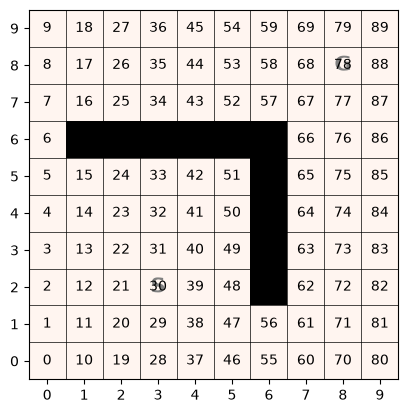

In [5]:
gym_env = gym.make('LMaze-v0', tabular=False)
env = gym_env.unwrapped
env.reset(seed=SEED)

env.image()

In [8]:
print(env.states())

[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 7), (1, 8), (1, 9), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 7), (2, 8), (2, 9), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 7), (3, 8), (3, 9), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 7), (4, 8), (4, 9), (5, 0), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 7), (5, 8), (5, 9), (6, 0), (6, 1), (6, 7), (6, 8), (6, 9), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]


## Define a Policy To Evaluate

I manually define the optimal policy that leads to the goal. I will use TD(0) to predict the value function for this policy.

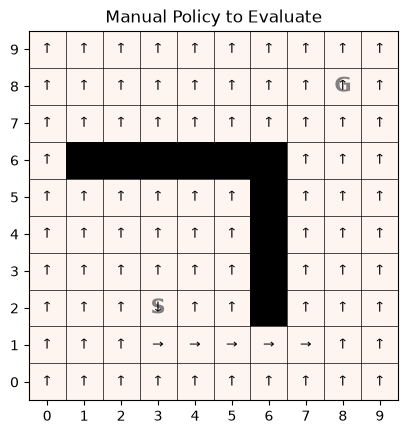

In [10]:
pol = np.full(len(env.states()), env.action2id('up'))
pol[[30]] = env.action2id('down')
pol[[29,38,47,56,61]] = env.action2id('right')
pol

env.image(policy = pol, title='Manual Policy to Evaluate')

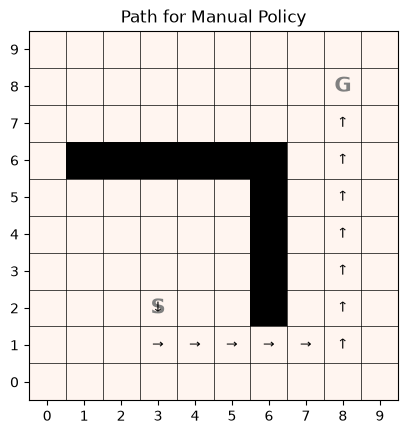

In [11]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

path = sample_episode(env, policy=pol, max_len=100, rng=rng)
env.image(policy=pol, episode=path, title='Path for Manual Policy')

## Prediction with Linear State Features

In [12]:
from gym_classics2.algorithms.linear_approximation import semi_gradient_TD0, v_hat

In [13]:
def linear_state_features(s, env):
    return np.concatenate([np.array([1]), np.array(s)])

In [14]:
w = semi_gradient_TD0(env, linear_state_features, pol, n=100, alpha=0.001, gamma=1, max_episode_length=1000)

Semi-Gradient TD(0): 100%|██████████| 100/100 [00:00<00:00, 3389.64it/s]


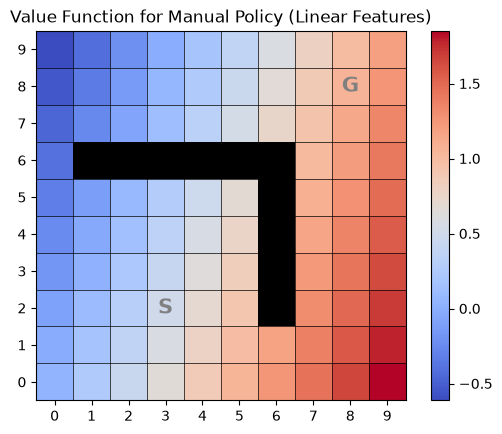

In [17]:
V = np.array([v_hat(s, w, env, linear_state_features) for s in env.states()])
env.image(V, title = "Value Function for Manual Policy (Linear Features)")

This value function has the problem, that a greedy policy would get stuck in the corner of the L-shaped wall!

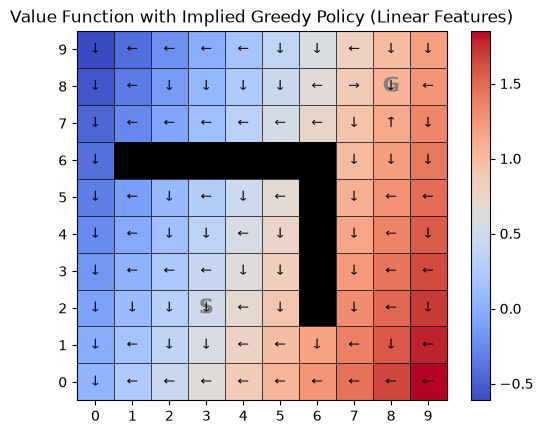

In [ ]:
#from gym_classics2.algorithms.policy import greedy_policy

# gym-classics2.algorithms.policy.greedy_policy is not available for non-tabular environments
# in the current version, so we implement it here.
from gym_classics2.algorithms.dynamic_programming import backup, random_argmax

def greedy_policy(V, env):
    policy = np.zeros(len(env.states()), dtype=np.int64)
    for s in env.states():
        Q_values = [backup(env, 1.0, V, s, a) for a in range(env.action_space.n)]
        policy[s] = random_argmax(Q_values, rng=rng)
    return policy

implied_policy = greedy_policy(V, env)
env.image(V, policy=implied_policy, title = "Value Function with Implied Greedy Policy (Linear Features)")

We can visualize the manually created value function using contours.

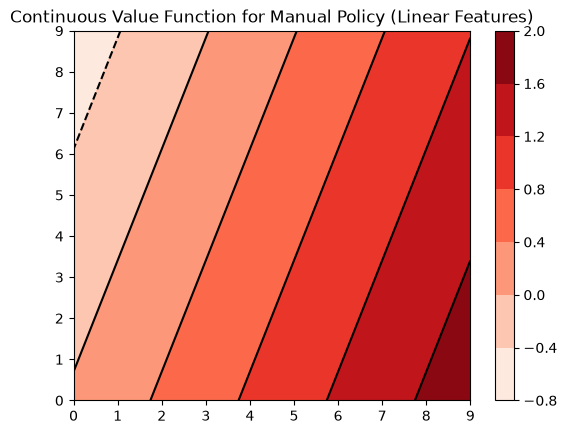

In [ ]:
show_value_function(w, linear_state_features, title = "Continuous Value Function for Manual Policy (Linear Features)")

Linear features are not able to express a value function consistent with the policy.

## Prediction with Fourier Basis Function Features

In [ ]:
from gym_classics2.algorithms.linear_approximation import transformation_fourier_basis

transform = transformation_fourier_basis([0, 0], [9, 9], order=2)

def fourier_state_features(state, env):
    return transform(state)

In [ ]:
w = semi_gradient_TD0(env, fourier_state_features, pol, n=100, alpha=0.001, gamma=1, max_episode_length=1000)

Semi-Gradient TD(0): 100%|██████████| 100/100 [00:00<00:00, 2206.80it/s]


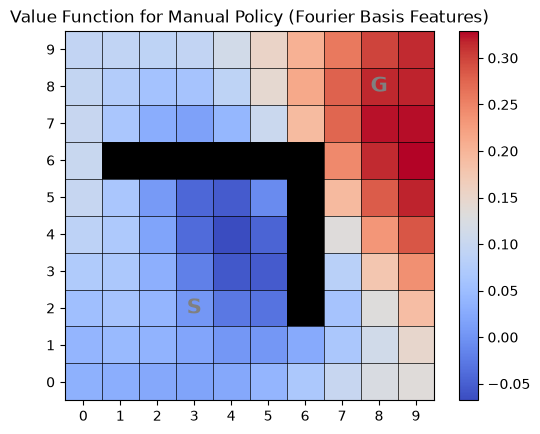

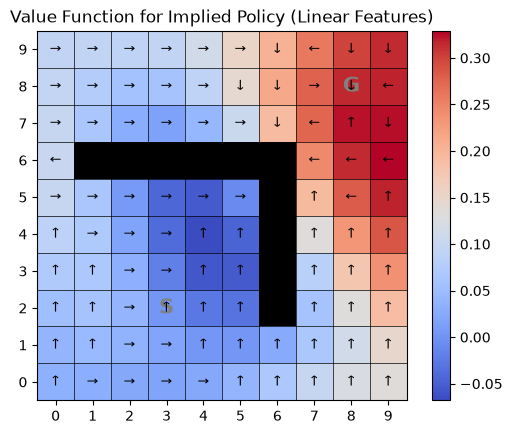

In [ ]:
V = np.array([v_hat(s, w, env, fourier_state_features) for s in env.states()])
env.image(V, title = "Value Function for Manual Policy (Fourier Basis Features)")
env.image(V, policy=greedy_policy(V, env), title = "Value Function for Implied Policy (Linear Features)")

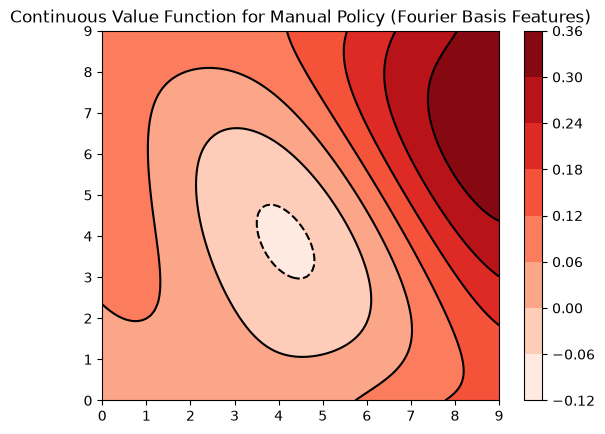

In [ ]:
show_value_function(w, fourier_state_features, title="Continuous Value Function for Manual Policy (Fourier Basis Features)")


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)